# A5 Stacking Comparison

This compares two stacking variants. With paired t-test, Wilcoxon signed-rank test, paired effect size, and bootstrap CI.


In [9]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon
import matplotlib.pyplot as plt


Find the project root and define file paths for the saved bootstrap metrics.


In [10]:
def find_project_root(start: Path) -> Path:
    for p in [start.resolve(), *start.resolve().parents]:
        if (p / "ml").exists() and (p / "reporting").exists():
            return p
    raise RuntimeError("Could not locate project root from current working directory.")

PROJECT_ROOT = find_project_root(Path.cwd())
A5_DIR = PROJECT_ROOT / "ml" / "models" / "research" / "A5"
REG_METRICS_FILE = A5_DIR / "reg_metrics_by_boot.pkl"
CLF_METRICS_FILE = A5_DIR / "clf_metrics_by_boot.pkl"

PROJECT_ROOT, A5_DIR


(WindowsPath('C:/Universitet/Machine Learning/4DT907/Project/machine_learning_project_4dt907'),
 WindowsPath('C:/Universitet/Machine Learning/4DT907/Project/machine_learning_project_4dt907/ml/models/research/A5'))

Load bootstrap metric artifacts and list available stacking methods.


In [11]:
def load_pickle(path: Path):
    with open(path, "rb") as f:
        return pickle.load(f)

if REG_METRICS_FILE.exists():
    reg_metrics_by_boot = load_pickle(REG_METRICS_FILE)
else:
    raise FileNotFoundError(f"Missing {REG_METRICS_FILE}")

if CLF_METRICS_FILE.exists():
    clf_metrics_by_boot = load_pickle(CLF_METRICS_FILE)
else:
    raise FileNotFoundError(f"Missing {CLF_METRICS_FILE}")

def methods_in(metrics_by_boot):
    return sorted({m for boot in metrics_by_boot.values() for m in boot.keys()})

def stacking_methods_only(metrics_by_boot):
    return sorted(m for m in methods_in(metrics_by_boot) if "stacking" in m.lower())

reg_stacking_methods = stacking_methods_only(reg_metrics_by_boot)
clf_stacking_methods = stacking_methods_only(clf_metrics_by_boot)

print("Loaded bootstrap metrics")
print("reg boots:", len(reg_metrics_by_boot), "| stacking methods:", reg_stacking_methods)
print("clf boots:", len(clf_metrics_by_boot), "| stacking methods:", clf_stacking_methods)


Loaded bootstrap metrics
reg boots: 10 | stacking methods: ['stacking_in_boot', 'stacking_passthrough_in_boot']
clf boots: 10 | stacking methods: ['stacking_in_boot', 'stacking_passthrough_in_boot']


Define paired statistical helper functions (t-test, Wilcoxon, CI, effect size).


In [12]:
def paired_series(metrics_by_boot, method_a, method_b, metric, higher_is_better=True):
    boots = sorted(metrics_by_boot.keys())
    a, b = [], []

    for bid in boots:
        if method_a not in metrics_by_boot[bid] or method_b not in metrics_by_boot[bid]:
            continue
        if metric not in metrics_by_boot[bid][method_a] or metric not in metrics_by_boot[bid][method_b]:
            continue
        a.append(float(metrics_by_boot[bid][method_a][metric]))
        b.append(float(metrics_by_boot[bid][method_b][metric]))

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if higher_is_better:
        a_hi, b_hi = a.copy(), b.copy()
    else:
        a_hi, b_hi = -a, -b

    return a, b, a_hi, b_hi


def bootstrap_ci_mean(samples, n_boot=5000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    samples = np.asarray(samples, dtype=float)
    n = len(samples)

    if n == 0:
        return np.nan, np.nan

    means = np.empty(n_boot, dtype=float)
    idx = np.arange(n)
    for i in range(n_boot):
        s = rng.choice(idx, size=n, replace=True)
        means[i] = float(np.mean(samples[s]))

    lo = float(np.quantile(means, alpha / 2))
    hi = float(np.quantile(means, 1 - alpha / 2))
    return lo, hi


def paired_stats_table(metrics_by_boot, method_a, method_b, metric_cfg, label):
    rows = []

    for metric, higher_is_better in metric_cfg.items():
        a, b, a_hi, b_hi = paired_series(metrics_by_boot, method_a, method_b, metric, higher_is_better)
        n = len(a)

        if n < 2:
            rows.append({
                "comparison": label,
                "metric": metric,
                "n_pairs": int(n),
                "mean_A_raw": np.nan,
                "mean_B_raw": np.nan,
                "mean_diff_hi(A-B)": np.nan,
                "ci95_low": np.nan,
                "ci95_high": np.nan,
                "t_stat": np.nan,
                "p_ttest": np.nan,
                "p_wilcoxon": np.nan,
                "cohen_d_paired": np.nan,
                "win_rate_A": np.nan,
            })
            continue

        diff = a_hi - b_hi
        diff_mean = float(np.mean(diff))
        ci_lo, ci_hi = bootstrap_ci_mean(diff)

        t_stat, p_ttest = ttest_rel(a_hi, b_hi, nan_policy="omit")

        try:
            _, p_w = wilcoxon(a_hi, b_hi, zero_method="wilcox", correction=False)
        except ValueError:
            p_w = np.nan

        diff_std = float(np.std(diff, ddof=1)) if n > 1 else np.nan
        d_paired = float(diff_mean / diff_std) if diff_std and np.isfinite(diff_std) and diff_std > 0 else np.nan
        win_rate_a = float(np.mean(diff > 0))

        rows.append({
            "comparison": label,
            "metric": metric,
            "n_pairs": int(n),
            "mean_A_raw": float(np.mean(a)),
            "mean_B_raw": float(np.mean(b)),
            "mean_diff_hi(A-B)": diff_mean,
            "ci95_low": ci_lo,
            "ci95_high": ci_hi,
            "t_stat": float(t_stat),
            "p_ttest": float(p_ttest),
            "p_wilcoxon": float(p_w) if pd.notna(p_w) else np.nan,
            "cohen_d_paired": d_paired,
            "win_rate_A": win_rate_a,
        })

    return pd.DataFrame(rows)


Set which two stacking variants to compare for regression and classification.


In [ ]:
# compareison of the two stacking variants
REG_METHOD_A = "stacking_in_boot"
REG_METHOD_B = "stacking_passthrough_in_boot"

CLF_METHOD_A = "stacking_in_boot"
CLF_METHOD_B = "stacking_passthrough_in_boot"

for m in [REG_METHOD_A, REG_METHOD_B]:
    if m not in reg_stacking_methods:
        raise KeyError(f"Regression stacking method '{m}' not found. Available: {reg_stacking_methods}")

for m in [CLF_METHOD_A, CLF_METHOD_B]:
    if m not in clf_stacking_methods:
        raise KeyError(f"Classification stacking method '{m}' not found. Available: {clf_stacking_methods}")

print("Regression comparison:", REG_METHOD_A, "vs", REG_METHOD_B)
print("Classification comparison:", CLF_METHOD_A, "vs", CLF_METHOD_B)


Regression comparison: stacking_in_boot vs stacking_passthrough_in_boot
Classification comparison: stacking_in_boot vs stacking_passthrough_in_boot


Compute and display regression stacking-vs-stacking comparison results.


In [14]:
reg_metric_cfg = {
    "r2": True,
    "rmse": False,
    "mae": False,
}

df_reg_compare = paired_stats_table(
    metrics_by_boot=reg_metrics_by_boot,
    method_a=REG_METHOD_A,
    method_b=REG_METHOD_B,
    metric_cfg=reg_metric_cfg,
    label=f"REG {REG_METHOD_A} vs {REG_METHOD_B}",
)

df_reg_compare


,comparison,metric,n_pairs,mean_A_raw,mean_B_raw,mean_diff_hi(A-B),ci95_low,ci95_high,t_stat,p_ttest,p_wilcoxon,cohen_d_paired,win_rate_A
0,REG stacking_in_boot vs stacking_passthrough_i...,r2,10,0.681295,0.687961,-0.006665,-0.009363,-0.003962,-4.595070,0.001300,0.001953,-1.453089,0.0
1,REG stacking_in_boot vs stacking_passthrough_i...,rmse,10,0.128160,0.126817,-0.001342,-0.001881,-0.000797,-4.589788,0.001309,0.001953,-1.451418,0.0
2,REG stacking_in_boot vs stacking_passthrough_i...,mae,10,0.092935,0.091628,-0.001307,-0.001786,-0.000842,-5.195852,0.000567,0.001953,-1.643073,0.0


Cell purpose: Compute and display classification stacking-vs-stacking comparison results.

"mean_diff_hi(A-B) > 0" means method A is better.

In [15]:
clf_metric_cfg = {
    "accuracy": True,
    "balanced_accuracy": True,
    "macro_f1": True,
    "weighted_f1": True,
    "log_loss": False,
}

df_clf_compare = paired_stats_table(
    metrics_by_boot=clf_metrics_by_boot,
    method_a=CLF_METHOD_A,
    method_b=CLF_METHOD_B,
    metric_cfg=clf_metric_cfg,
    label=f"CLF {CLF_METHOD_A} vs {CLF_METHOD_B}",
)

df_clf_compare


,comparison,metric,n_pairs,mean_A_raw,mean_B_raw,mean_diff_hi(A-B),ci95_low,ci95_high,t_stat,p_ttest,p_wilcoxon,cohen_d_paired,win_rate_A
0,CLF stacking_in_boot vs stacking_passthrough_i...,accuracy,10,0.544638,0.553913,-0.009275,-0.019420,0.000870,-1.637739,1.359013e-01,0.140625,-0.517899,0.3
1,CLF stacking_in_boot vs stacking_passthrough_i...,balanced_accuracy,10,0.540187,0.556003,-0.015817,-0.034356,-0.000066,-1.704097,1.225600e-01,0.193359,-0.538883,0.3
2,CLF stacking_in_boot vs stacking_passthrough_i...,macro_f1,10,0.422638,0.425548,-0.002910,-0.014782,0.007107,-0.483961,6.399718e-01,0.921875,-0.153042,0.6
3,CLF stacking_in_boot vs stacking_passthrough_i...,weighted_f1,10,0.569554,0.567203,0.002351,-0.005829,0.010644,0.515996,6.182940e-01,0.845703,0.163172,0.5
4,CLF stacking_in_boot vs stacking_passthrough_i...,log_loss,10,1.420486,1.283599,-0.136887,-0.145345,-0.127568,-29.458070,2.922130e-10,0.001953,-9.315460,0.0


Plot optional distributions of paired metric differences.


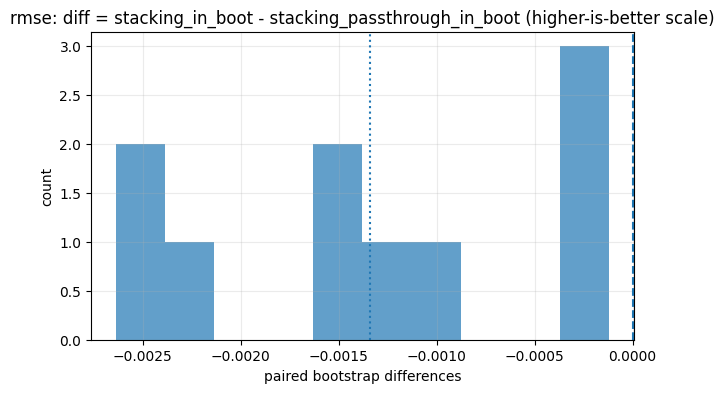

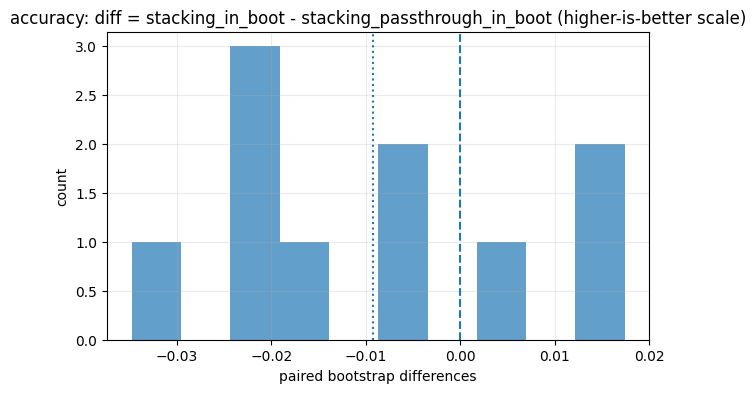

In [16]:
def plot_diff(metrics_by_boot, method_a, method_b, metric, higher_is_better=True, bins=10):
    a, b, a_hi, b_hi = paired_series(metrics_by_boot, method_a, method_b, metric, higher_is_better)
    if len(a_hi) < 2:
        print(f"Not enough pairs for {metric}")
        return

    diff = a_hi - b_hi
    plt.figure(figsize=(7, 4))
    plt.hist(diff, bins=bins, alpha=0.7)
    plt.axvline(0.0, linestyle="--")
    plt.axvline(float(np.mean(diff)), linestyle=":")
    plt.title(f"{metric}: diff = {method_a} - {method_b} (higher-is-better scale)")
    plt.xlabel("paired bootstrap differences")
    plt.ylabel("count")
    plt.grid(True, alpha=0.25)
    plt.show()

plot_diff(reg_metrics_by_boot, REG_METHOD_A, REG_METHOD_B, "rmse", higher_is_better=False)
plot_diff(clf_metrics_by_boot, CLF_METHOD_A, CLF_METHOD_B, "accuracy", higher_is_better=True)


Print a short human-readable conclusion from the statistical tables.


In [17]:
def quick_conclusion(df, method_a, method_b):
    out = []
    for _, r in df.iterrows():
        winner = method_a if r['mean_diff_hi(A-B)'] > 0 else method_b
        sig = 'significant' if pd.notna(r['p_ttest']) and r['p_ttest'] < 0.05 else 'not_significant'
        out.append(f"{r['metric']}: {winner}, {sig}, mean_diff_hi={r['mean_diff_hi(A-B)']:.4g}, p={r['p_ttest']:.4g}")
    return out

print('REG')
for line in quick_conclusion(df_reg_compare, REG_METHOD_A, REG_METHOD_B):
    print('-', line)

print('')
print('CLF')
for line in quick_conclusion(df_clf_compare, CLF_METHOD_A, CLF_METHOD_B):
    print('-', line)


REG
- r2: stacking_passthrough_in_boot, significant, mean_diff_hi=-0.006665, p=0.0013
- rmse: stacking_passthrough_in_boot, significant, mean_diff_hi=-0.001342, p=0.001309
- mae: stacking_passthrough_in_boot, significant, mean_diff_hi=-0.001307, p=0.0005672

CLF
- accuracy: stacking_passthrough_in_boot, not_significant, mean_diff_hi=-0.009275, p=0.1359
- balanced_accuracy: stacking_passthrough_in_boot, not_significant, mean_diff_hi=-0.01582, p=0.1226
- macro_f1: stacking_passthrough_in_boot, not_significant, mean_diff_hi=-0.00291, p=0.64
- weighted_f1: stacking_in_boot, not_significant, mean_diff_hi=0.002351, p=0.6183
- log_loss: stacking_passthrough_in_boot, significant, mean_diff_hi=-0.1369, p=2.922e-10
